In [2]:
import importlib

packages = ["pandas", "numpy", "scipy", "matplotlib", "seaborn",
            "sklearn", "statsmodels", "xgboost", "lightgbm",
            "folium", "plotly", "holidays", "shap"]

for p in packages:
    try:
        m = importlib.import_module(p)
        print(f"OK       {p} {getattr(m, '__version__', '')}")
    except ImportError:
        print(f"MISSING  {p}")

OK       pandas 3.1.0
OK       numpy 2.4.6
OK       scipy 1.17.1
OK       matplotlib 3.11.0
OK       seaborn 0.13.2
OK       sklearn 1.5.1
OK       statsmodels 0.15.0
OK       xgboost 3.2.0
OK       lightgbm 4.7.0
OK       folium 0.20.0
OK       plotly 7.1.0
OK       holidays 0.107


c:\Users\HP\.conda\envs\fmcg\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK       shap 0.51.0


In [3]:

import pandas as pd
import sqlalchemy
print(pd.__version__, sqlalchemy.__version__)

3.1.0 2.1.8


In [4]:
#Step 1: Data Preparation and SQL Retrieval

from sqlalchemy import create_engine


In [5]:
import pandas as pd
FMCG_Sales_DF= pd.read_csv(r"C:\Users\HP\Documents\PROJECT_DATA_LADDER\fmcg_sales_3years_1M_rows.csv" )
Climate_Data_DF=pd.read_csv(r"C:\Users\HP\Documents\PROJECT_DATA_LADDER\climate_features.csv")


In [6]:

FMCG_Sales_DF.shape
FMCG_Sales_DF.info()
FMCG_Sales_DF.describe
FMCG_Sales_DF.head()




<class 'pandas.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 33 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   date            1100000 non-null  str    
 1   year            1100000 non-null  int64  
 2   month           1100000 non-null  int64  
 3   day             1100000 non-null  int64  
 4   weekofyear      1100000 non-null  int64  
 5   weekday         1100000 non-null  int64  
 6   is_weekend      1100000 non-null  int64  
 7   is_holiday      1100000 non-null  int64  
 8   temperature     1100000 non-null  float64
 9   rain_mm         1100000 non-null  float64
 10  store_id        1100000 non-null  str    
 11  country         1100000 non-null  str    
 12  city            1100000 non-null  str    
 13  channel         1100000 non-null  str    
 14  latitude        1100000 non-null  float64
 15  longitude       1100000 non-null  float64
 16  sku_id          1100000 non-null  str    
 17  

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [7]:
Climate_Data_DF.shape
Climate_Data_DF.describe

<bound method DataFrame.describe of                ID   deathdate  elevation  hot_days_30d  max_daily_rain_30d  \
0     ID_1FE951BD  2007-10-02       1114             0           20.394434   
1     ID_5927A443  2008-01-05       1145             0           16.994602   
2     ID_C4E67025  2008-02-14       1145             0           15.661628   
3     ID_44DC5CE9  2008-02-15       1145             0           15.661628   
4     ID_33C677BB  2008-02-15       1660             0           13.468142   
...           ...         ...        ...           ...                 ...   
4171  ID_911AD860  2022-04-29       1163             0           58.102787   
4172  ID_CAC43CF7  2022-04-29       1114             0           17.993561   
4173  ID_A3FBDDCC  2022-05-05       1111             0           22.989155   
4174  ID_A6652C52  2022-05-12       1201             0           26.320398   
4175  ID_82DEF492  2022-05-17       1111             0           24.176552   

      ndvi_30d  ndvi_90d  r

In [8]:
Climate_Data_DF.head()

,ID,deathdate,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
0,ID_1FE951BD,2007-10-02,1114,0,20.394434,0.72205,0.72910,18,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043
1,ID_5927A443,2008-01-05,1145,0,16.994602,0.60815,0.66985,7,71.885960,0.000000,268.439276,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455
2,ID_C4E67025,2008-02-14,1145,0,15.661628,0.59290,0.61335,20,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068
3,ID_44DC5CE9,2008-02-15,1145,0,15.661628,0.59290,0.61335,19,98.524518,29.091067,229.370640,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068
4,ID_33C677BB,2008-02-15,1660,0,13.468142,0.53380,0.71580,13,84.030272,25.698621,186.079130,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257


In [9]:
Climate_Data_DF.info(
    
)

<class 'pandas.DataFrame'>
RangeIndex: 4176 entries, 0 to 4175
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   4176 non-null   str    
 1   deathdate            4176 non-null   str    
 2   elevation            4176 non-null   int64  
 3   hot_days_30d         4176 non-null   int64  
 4   max_daily_rain_30d   4176 non-null   float64
 5   ndvi_30d             4176 non-null   float64
 6   ndvi_90d             4176 non-null   float64
 7   rain_days_30d        4176 non-null   int64  
 8   rain_sum_30d         4176 non-null   float64
 9   rain_sum_7d          4176 non-null   float64
 10  rain_sum_90d         4176 non-null   float64
 11  slope                4176 non-null   float64
 12  tavg_30d             4176 non-null   float64
 13  tavg_7d              4176 non-null   float64
 14  tavg_90d             4176 non-null   float64
 15  temp_range_mean_30d  4176 non-null   float64
 16 

In [10]:
import pandas as pd, sqlalchemy, sys
print(pd.__version__, sqlalchemy.__version__)
print(sqlalchemy.__file__)
print(sys.executable)

3.1.0 2.1.8
c:\Users\HP\.conda\envs\fmcg\Lib\site-packages\sqlalchemy\__init__.py
c:\Users\HP\.conda\envs\fmcg\python.exe


In [11]:
print(FMCG_Sales_DF.columns.tolist())
print(Climate_Data_DF.columns.tolist())

['date', 'year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend', 'is_holiday', 'temperature', 'rain_mm', 'store_id', 'country', 'city', 'channel', 'latitude', 'longitude', 'sku_id', 'sku_name', 'category', 'subcategory', 'brand', 'units_sold', 'list_price', 'discount_pct', 'promo_flag', 'gross_sales', 'net_sales', 'stock_on_hand', 'stock_out_flag', 'lead_time_days', 'supplier_id', 'purchase_cost', 'margin_pct']
['ID', 'deathdate', 'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d', 'temp_range_mean_30d', 'tmax_30d', 'tmin_30d']


In [12]:
print(FMCG_Sales_DF.nunique())

date               1095
year                  3
month                12
day                  31
weekofyear           53
weekday               7
is_weekend            2
is_holiday            2
temperature         710
rain_mm             559
store_id             13
country               7
city                  9
channel               4
latitude             13
longitude            13
sku_id              102
sku_name            102
category              5
subcategory          17
brand                 6
units_sold          516
list_price           99
discount_pct          5
promo_flag            2
gross_sales       15354
net_sales         29938
stock_on_hand       640
stock_out_flag        2
lead_time_days       17
supplier_id          60
purchase_cost      1062
margin_pct          601
dtype: int64


In [13]:
import sys
!{sys.executable} -m pip install --upgrade "sqlalchemy>=2.0.36"

In [14]:
import sqlalchemy
print(sqlalchemy.__version__, sqlalchemy.__file__)

2.1.8 c:\Users\HP\.conda\envs\fmcg\Lib\site-packages\sqlalchemy\__init__.py


In [15]:
from sqlalchemy import create_engine

engine = create_engine('sqlite:///FMCG_sales_and_Climate.db')

FMCG_Sales_DF.to_sql("FMCG_Sales_DF", engine, if_exists="replace", index=False, chunksize=10000)
Climate_Data_DF.to_sql("Climate_Data_DF", engine, if_exists="replace", index=False)

4176

In [16]:
from sqlalchemy import text

with engine.connect() as conn:
    print(pd.read_sql(text("SELECT COUNT(*) AS n FROM FMCG_Sales_DF"), conn))
    print(pd.read_sql(text("SELECT COUNT(*) AS n FROM Climate_Data_DF"), conn))

         n
0  1100000
      n
0  4176


In [17]:
print(FMCG_Sales_DF.columns.tolist())
print(Climate_Data_DF.columns.tolist())

['date', 'year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend', 'is_holiday', 'temperature', 'rain_mm', 'store_id', 'country', 'city', 'channel', 'latitude', 'longitude', 'sku_id', 'sku_name', 'category', 'subcategory', 'brand', 'units_sold', 'list_price', 'discount_pct', 'promo_flag', 'gross_sales', 'net_sales', 'stock_on_hand', 'stock_out_flag', 'lead_time_days', 'supplier_id', 'purchase_cost', 'margin_pct']
['ID', 'deathdate', 'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d', 'temp_range_mean_30d', 'tmax_30d', 'tmin_30d']


In [18]:
print(FMCG_Sales_DF.nunique())

date               1095
year                  3
month                12
day                  31
weekofyear           53
weekday               7
is_weekend            2
is_holiday            2
temperature         710
rain_mm             559
store_id             13
country               7
city                  9
channel               4
latitude             13
longitude            13
sku_id              102
sku_name            102
category              5
subcategory          17
brand                 6
units_sold          516
list_price           99
discount_pct          5
promo_flag            2
gross_sales       15354
net_sales         29938
stock_on_hand       640
stock_out_flag        2
lead_time_days       17
supplier_id          60
purchase_cost      1062
margin_pct          601
dtype: int64


In [19]:
#checking null values and imputing  with medians
nulls = FMCG_Sales_DF.isna().sum()
print(nulls[nulls > 0])

Series([], dtype: int64)


In [20]:
print((FMCG_Sales_DF["units_sold"] < 0).sum(), (FMCG_Sales_DF["list_price"] <= 0).sum())
print((FMCG_Sales_DF[["latitude", "longitude"]] == 0).sum())

0 0
latitude     0
longitude    0
dtype: int64


In [21]:
print(FMCG_Sales_DF.isna().sum().sum())

0


In [22]:
for c in ["channel", "country"]:
    print(c, "->", FMCG_Sales_DF[c].nunique(), "unique")
    print(FMCG_Sales_DF[c].value_counts(dropna=False))
    print()

channel -> 4 unique
channel
Hypermarket    525600
Supermarket    262800
E-commerce     262800
Convenience     48800
Name: count, dtype: int64

country -> 7 unique
country
Italy          350400
Spain          262800
Germany        175200
Poland          87600
France          87600
Austria         87600
Netherlands     48800
Name: count, dtype: int64



In [23]:
cat_cols = FMCG_Sales_DF.select_dtypes(include=["object", "string", "category"]).columns.tolist()
print(cat_cols)

['date', 'store_id', 'country', 'city', 'channel', 'sku_id', 'sku_name', 'category', 'subcategory', 'brand', 'supplier_id']


In [24]:
for c in cat_cols:
    print(c, "->", FMCG_Sales_DF[c].nunique())

date -> 1095
store_id -> 13
country -> 7
city -> 9
channel -> 4
sku_id -> 102
sku_name -> 102
category -> 5
subcategory -> 17
brand -> 6
supplier_id -> 60


In [25]:
label_cols = ["country", "city", "channel", "sku_name", "category", "subcategory", "brand"]

for c in label_cols:
    FMCG_Sales_DF[c] = FMCG_Sales_DF[c].astype(str).str.strip().str.title()

In [26]:
for c in ["sku_id", "store_id", "supplier_id"]:
    FMCG_Sales_DF[c] = FMCG_Sales_DF[c].astype(str).str.strip()

In [27]:
for c in label_cols:
    print(c, FMCG_Sales_DF[c].nunique())
    print(FMCG_Sales_DF[c].value_counts().head(20))
    print()

country 7
country
Italy          350400
Spain          262800
Germany        175200
Poland          87600
France          87600
Austria         87600
Netherlands     48800
Name: count, dtype: int64

city 9
city
Berlin       175200
Rome         175200
Milan        175200
Barcelona    175200
Warsaw        87600
Paris         87600
Vienna        87600
Madrid        87600
Amsterdam     48800
Name: count, dtype: int64

channel 4
channel
Hypermarket    525600
Supermarket    262800
E-Commerce     262800
Convenience     48800
Name: count, dtype: int64

sku_name 102
sku_name
Brandb Energy Drink    14235
Brandc Biscuits        14235
Branda Soda            14235
Brandf Soap            14235
Brandf Soda            13140
Branda Milk            13140
Brandc Water           13140
Brande Cheese          13140
Brandb Milk            13140
Brandc Shampoo         13140
Branda Toothpaste      13140
Brandd Chips           13140
Brandb Shampoo         12045
Brandf Water           12045
Brande Chocolate     

In [32]:
FMCG_Sales_DF.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [ ]:
#Statistical Baseline
#Calculate the mean, median, and standard deviation for sales. Pay close attention to the Coefficient of Variation (CV) to identify which regions suffer from the highest demand volatility.

FMCG_Sales_DF_AGGREGATE =FMCG_Sales_DF.groupby("country")['net_sales'].agg(["mean","median","std"])
FMCG_Sales_DF["date"] = pd.to_datetime(FMCG_Sales_DF["date"])
print(FMCG_Sales_DF_AGGREGATE)




                   mean  median         std
country                                    
Austria      491.096187  308.20  480.524417
France       486.319778  310.46  467.171925
Germany      505.282871  334.95  481.236261
Italy        391.532751  251.92  384.095747
Netherlands  256.478475  166.40  248.019075
Poland       483.850029  322.00  456.514583
Spain        406.030316  269.44  387.661182


In [37]:
#Coefficient of Variation (CV) to identify which regions suffer from the highest demand volatility.
FMCG_Sales_DF_COEFF=FMCG_Sales_DF_AGGREGATE["std"]/FMCG_Sales_DF_AGGREGATE["mean"]
FMCG_Sales_DF_COEFF_SORTED=FMCG_Sales_DF_COEFF.sort_values(ascending=False)
print(FMCG_Sales_DF_COEFF_SORTED)

country
Italy          0.981005
Austria        0.978473
Netherlands    0.967017
France         0.960627
Spain          0.954759
Germany        0.952410
Poland         0.943504
dtype: float64


In [41]:
#Geospatial and Logistics Analysis
import matplotlib.pyplot as plt
import numpy as np
geo_table = FMCG_Sales_DF.groupby(["store_id", "country", "city", "channel", "latitude", "longitude"]).agg(
    net_sales=("net_sales", "sum"),
    units_sold=("units_sold", "sum"),
    avg_lead_time=("lead_time_days", "mean"),
    lead_time_std=("lead_time_days", "std"),
    stockout_rate=("stock_out_flag", "mean"),
).reset_index()

geo_table["lead_time_cv"] = geo_table["lead_time_std"] / geo_table["avg_lead_time"]
print(geo_table.head())

    store_id  country    city      channel  latitude  longitude    net_sales  \
0  STORE0001  Germany  Berlin  Hypermarket  52.52586   13.39071  41939805.83   
1  STORE0002    Italy    Rome  Supermarket  41.94012   12.50588  30231862.00   
2  STORE0003    Italy   Milan  Supermarket  45.44037    9.20313  28752564.26   
3  STORE0004  Germany  Berlin  Hypermarket  52.50051   13.42074  46585753.18   
4  STORE0005   Poland  Warsaw  Hypermarket  52.25287   20.99579  42385262.52   

   units_sold  avg_lead_time  lead_time_std  stockout_rate  lead_time_cv  
0     5681442       6.505559       2.008712       0.030103      0.308769  
1     4249838       6.498550       2.012052       0.030525      0.309616  
2     4019467       6.496267       2.013581       0.029486      0.309960  
3     6057129       6.504886       2.014372       0.030080      0.309671  
4     5860180       6.506039       2.015932       0.029578      0.309856  


In [43]:
store_table = FMCG_Sales_DF.groupby(["store_id", "country", "city", "latitude", "longitude"]).agg(
    net_sales=("net_sales", "sum"),
    units_sold=("units_sold", "sum"),
    avg_lead_time=("lead_time_days", "mean"),
    lead_time_std=("lead_time_days", "std"),
    stockout_rate=("stock_out_flag", "mean"),
).reset_index()

print(len(store_table), "stores")
print(store_table.head())


13 stores
    store_id  country    city  latitude  longitude    net_sales  units_sold  \
0  STORE0001  Germany  Berlin  52.52586   13.39071  41939805.83     5681442   
1  STORE0002    Italy    Rome  41.94012   12.50588  30231862.00     4249838   
2  STORE0003    Italy   Milan  45.44037    9.20313  28752564.26     4019467   
3  STORE0004  Germany  Berlin  52.50051   13.42074  46585753.18     6057129   
4  STORE0005   Poland  Warsaw  52.25287   20.99579  42385262.52     5860180   

   avg_lead_time  lead_time_std  stockout_rate  
0       6.505559       2.008712       0.030103  
1       6.498550       2.012052       0.030525  
2       6.496267       2.013581       0.029486  
3       6.504886       2.014372       0.030080  
4       6.506039       2.015932       0.029578  


In [44]:
import sys
!{sys.executable} -m pip install folium

In [51]:
import folium
from folium.plugins import HeatMap

heat_data = store_table[["latitude", "longitude", "units_sold"]].dropna().values.tolist()

m = folium.Map(
    location=[store_table["latitude"].mean(), store_table["longitude"].mean()],
    zoom_start=2,
)
HeatMap(heat_data, radius=18, blur=15).add_to(m)
m
m.save(r"C:\Users\HP\Documents\sales_heatmap.html")



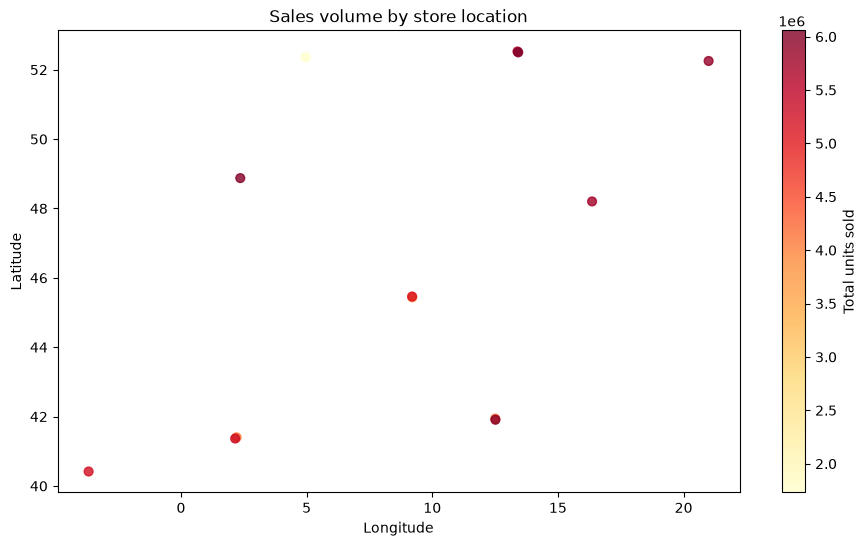

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))
sc = plt.scatter(store_table["longitude"], store_table["latitude"],
                 c=store_table["units_sold"], s=40, cmap="YlOrRd", alpha=0.8)
plt.colorbar(sc, label="Total units sold")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sales volume by store location")
plt.show()

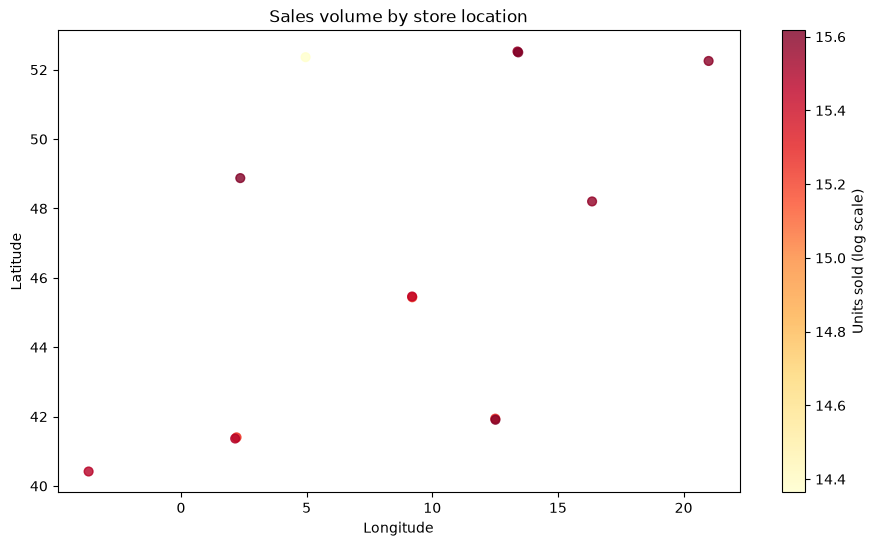

In [52]:

plt.figure(figsize=(11, 6))
sc = plt.scatter(store_table["longitude"], store_table["latitude"],
                 c=np.log1p(store_table["units_sold"]), s=40, cmap="YlOrRd", alpha=0.8)
plt.colorbar(sc, label="Units sold (log scale)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sales volume by store location")
plt.show()

In [54]:
demand_cut = store_table["units_sold"].quantile(0.75)
var_cut = store_table["lead_time_std"].quantile(0.75)

deserts = store_table[(store_table["units_sold"] >= demand_cut) &
                      (store_table["lead_time_std"] >= var_cut)]
print(deserts)

print(len(deserts), "logistics deserts")
print(deserts["country"].value_counts())
deserts = store_table[(store_table["units_sold"] >= demand_cut) &
                      (store_table["lead_time_std"] >= var_cut)]

print(len(deserts), "logistics deserts")
print(deserts["country"].value_counts())

    store_id country    city  latitude  longitude    net_sales  units_sold  \
4  STORE0005  Poland  Warsaw  52.25287   20.99579  42385262.52     5860180   

   avg_lead_time  lead_time_std  stockout_rate  
4       6.506039       2.015932       0.029578  
1 logistics deserts
country
Poland    1
Name: count, dtype: int64
1 logistics deserts
country
Poland    1
Name: count, dtype: int64


In [ ]:
#Segmentation Framework: ABC/XYZ Analysis
#ABC ANALYSIS

df = FMCG_Sales_DF
df["date"] = pd.to_datetime(df["date"])

sku_rev = df.groupby("sku_id")["net_sales"].sum().sort_values(ascending=False).reset_index()
sku_rev["share"] = sku_rev["net_sales"] / sku_rev["net_sales"].sum()
sku_rev["cum_before"] = sku_rev["share"].cumsum() - sku_rev["share"]

sku_rev["ABC"] = np.where(sku_rev["cum_before"] < 0.80, "A",
                  np.where(sku_rev["cum_before"] < 0.95, "B", "C"))

print(sku_rev["ABC"].value_counts())
print(sku_rev.groupby("ABC")["share"].sum()) 

ABC
A    50
B    29
C    23
Name: count, dtype: int64
ABC
A    0.800678
B    0.152516
C    0.046806
Name: share, dtype: float64


In [56]:
#XYZ ANALYSIS

df["month"] = df["date"].dt.to_period("M")

monthly = df.pivot_table(index="sku_id", columns="month", values="units_sold",
                         aggfunc="sum", fill_value=0)

xyz = pd.DataFrame({"cv": monthly.std(axis=1) / monthly.mean(axis=1)}).reset_index()
xyz["XYZ"] = np.where(xyz["cv"] <= 0.5, "X", np.where(xyz["cv"] <= 1.0, "Y", "Z"))

print(xyz["cv"].describe())
print(xyz["XYZ"].value_counts())


count    102.000000
mean       0.107071
std        0.072538
min        0.029348
25%        0.037405
50%        0.076353
75%        0.197504
max        0.241876
Name: cv, dtype: float64
XYZ
X    102
Name: count, dtype: int64
